# Library Installation and Version Verification

In [41]:
!pip install langchain chromadb google-generativeai scikit-learn -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.ensemble import IsolationForest
from datetime import datetime, timedelta
import random
import json
import sys

print("Python          :", sys.version)
print("NumPy           :", np.__version__)
print("Pandas          :", pd.__version__)
print("Scikit-learn    :", __import__('sklearn').__version__)

Python          : 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
NumPy           : 2.4.6
Pandas          : 3.0.5
Scikit-learn    : 1.9.0



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Constants, Agent Nodes, and Configuration

In [42]:
AGENT_NODES = ["Monitoring Node", "Context Retrieval Node",
               "Strategy Generation Node", "Auditor Node", "Execution Node"]

EXCEPTION_TYPES = ["Delay", "Damaged Goods", "Weather Disruption",
                   "Customs Hold", "Carrier Failure", "Inventory Shortage"]

SEVERITY_LEVELS = ["Low", "Medium", "High", "Critical"]

SHIPMENT_STATUS = ["In Transit", "Delayed", "Delivered", "Exception", "Pending"]

ROUTES = ["Mumbai-Delhi", "Chennai-Bangalore", "Kolkata-Mumbai",
          "Delhi-Chennai", "Hyderabad-Pune", "Bangalore-Hyderabad"]

RESOLUTION_DIMENSIONS = ["Speed", "Cost", "Sustainability"]

WEATHER_CONDITIONS = ["Clear", "Rain", "Storm", "Fog", "Cyclone", "Flood"]

COMPLIANCE_RULES = ["weight_limit", "temperature_range",
                    "delivery_deadline", "carrier_certification", "customs_clearance"]

NUM_SHIPMENTS = 200
NUM_EXCEPTIONS = 100
NUM_WEATHER_EVENTS = 150

print("Agent Nodes          :", AGENT_NODES)
print("Exception Types      :", EXCEPTION_TYPES)
print("Severity Levels      :", SEVERITY_LEVELS)
print("Routes               :", ROUTES)
print("Resolution Dimensions:", RESOLUTION_DIMENSIONS)
print("Weather Conditions   :", WEATHER_CONDITIONS)

Agent Nodes          : ['Monitoring Node', 'Context Retrieval Node', 'Strategy Generation Node', 'Auditor Node', 'Execution Node']
Exception Types      : ['Delay', 'Damaged Goods', 'Weather Disruption', 'Customs Hold', 'Carrier Failure', 'Inventory Shortage']
Severity Levels      : ['Low', 'Medium', 'High', 'Critical']
Routes               : ['Mumbai-Delhi', 'Chennai-Bangalore', 'Kolkata-Mumbai', 'Delhi-Chennai', 'Hyderabad-Pune', 'Bangalore-Hyderabad']
Resolution Dimensions: ['Speed', 'Cost', 'Sustainability']
Weather Conditions   : ['Clear', 'Rain', 'Storm', 'Fog', 'Cyclone', 'Flood']


# Shipment Data Simulation

In [43]:
random.seed(42)
np.random.seed(42)

shipments = []
for i in range(1, NUM_SHIPMENTS + 1):
    dispatch_date = datetime(2024, 1, 1) + timedelta(days=random.randint(0, 180))
    expected_delivery = dispatch_date + timedelta(days=random.randint(2, 10))
    actual_delivery = expected_delivery + timedelta(days=random.randint(-1, 5))
    delay_days = max(0, (actual_delivery - expected_delivery).days)
    shipments.append({
        "shipment_id": f"SHP_{i:04d}",
        "route": random.choice(ROUTES),
        "status": random.choice(SHIPMENT_STATUS),
        "dispatch_date": dispatch_date.strftime("%Y-%m-%d"),
        "expected_delivery": expected_delivery.strftime("%Y-%m-%d"),
        "actual_delivery": actual_delivery.strftime("%Y-%m-%d"),
        "delay_days": delay_days,
        "weight_kg": round(random.uniform(10, 1000), 2),
        "temperature_c": round(random.uniform(-5, 35), 2),
        "carrier": f"Carrier_{random.randint(1, 10):02d}",
        "cost_usd": round(random.uniform(500, 10000), 2)
    })

shipments_df = pd.DataFrame(shipments)
shipments_df.to_csv("shipments.csv", index=False)

print("Shipments Generated  :", len(shipments_df))
print("Columns              :", list(shipments_df.columns))
print(shipments_df.head(5).to_string())

Shipments Generated  : 200
Columns              : ['shipment_id', 'route', 'status', 'dispatch_date', 'expected_delivery', 'actual_delivery', 'delay_days', 'weight_kg', 'temperature_c', 'carrier', 'cost_usd']
  shipment_id                route      status dispatch_date expected_delivery actual_delivery  delay_days  weight_kg  temperature_c     carrier  cost_usd
0    SHP_0001  Bangalore-Hyderabad   Delivered    2024-06-12        2024-06-15      2024-06-14           0     252.44           0.58  Carrier_02   6928.65
1    SHP_0002        Delhi-Chennai  In Transit    2024-05-19        2024-05-22      2024-05-25           3      39.50           3.75  Carrier_09   6219.18
2    SHP_0003  Bangalore-Hyderabad     Pending    2024-05-23        2024-05-28      2024-06-01           4     425.32          12.97  Carrier_05   8189.59
3    SHP_0004        Delhi-Chennai   Delivered    2024-01-02        2024-01-06      2024-01-10           4     285.09           3.61  Carrier_06   1471.00
4    SHP_0005   

# Exception and Weather Event Data Simulation

In [44]:
exceptions = []
for i in range(1, NUM_EXCEPTIONS + 1):
    detected_date = datetime(2024, 1, 1) + timedelta(days=random.randint(0, 180))
    resolution_time = random.randint(1, 72)
    exceptions.append({
        "exception_id": f"EXC_{i:04d}",
        "shipment_id": f"SHP_{random.randint(1, NUM_SHIPMENTS):04d}",
        "exception_type": random.choice(EXCEPTION_TYPES),
        "severity": random.choice(SEVERITY_LEVELS),
        "detected_date": detected_date.strftime("%Y-%m-%d"),
        "resolution_time_hours": resolution_time,
        "resolved": random.choice([True, False]),
        "agent_node": random.choice(AGENT_NODES),
        "resolution_dimension": random.choice(RESOLUTION_DIMENSIONS)
    })

weather_events = []
for i in range(1, NUM_WEATHER_EVENTS + 1):
    event_date = datetime(2024, 1, 1) + timedelta(days=random.randint(0, 180))
    weather_events.append({
        "event_id": f"WEA_{i:04d}",
        "route": random.choice(ROUTES),
        "condition": random.choice(WEATHER_CONDITIONS),
        "severity_score": round(random.uniform(1, 10), 2),
        "event_date": event_date.strftime("%Y-%m-%d"),
        "duration_hours": random.randint(1, 48),
        "shipments_affected": random.randint(0, 15)
    })

exceptions_df = pd.DataFrame(exceptions)
weather_df = pd.DataFrame(weather_events)

exceptions_df.to_csv("exceptions.csv", index=False)
weather_df.to_csv("weather_events.csv", index=False)

print("Exceptions Generated     :", len(exceptions_df))
print("Weather Events Generated :", len(weather_df))
print()
print(exceptions_df.head(5).to_string())

Exceptions Generated     : 100
Weather Events Generated : 150

  exception_id shipment_id      exception_type  severity detected_date  resolution_time_hours  resolved              agent_node resolution_dimension
0     EXC_0001    SHP_0071  Inventory Shortage       Low    2024-03-31                     56      True            Auditor Node                 Cost
1     EXC_0002    SHP_0008       Damaged Goods  Critical    2024-05-11                     21      True  Context Retrieval Node                Speed
2     EXC_0003    SHP_0093        Customs Hold       Low    2024-03-01                     47      True            Auditor Node                 Cost
3     EXC_0004    SHP_0196               Delay    Medium    2024-04-05                     57     False            Auditor Node                 Cost
4     EXC_0005    SHP_0064               Delay       Low    2024-06-15                     36      True            Auditor Node       Sustainability


# SOP and Historical Precedent Document Structure

In [45]:
sop_documents = [
    {
        "doc_id": "SOP_001",
        "title": "Weather Disruption Response Protocol",
        "category": "Weather",
        "content": "When weather severity score exceeds 7.0, reroute shipments via alternate carriers. Notify stakeholders within 2 hours. Document all affected shipment IDs.",
        "applicable_exceptions": ["Weather Disruption", "Delay"]
    },
    {
        "doc_id": "SOP_002",
        "title": "Customs Hold Resolution Procedure",
        "category": "Customs",
        "content": "Engage customs broker within 4 hours of hold detection. Submit documentation package including invoice, packing list, and certificate of origin. Escalate to compliance team if unresolved after 24 hours.",
        "applicable_exceptions": ["Customs Hold"]
    },
    {
        "doc_id": "SOP_003",
        "title": "Carrier Failure Contingency Plan",
        "category": "Carrier",
        "content": "Identify backup carrier from approved vendor list within 1 hour. Transfer shipment manifest and custody documents. Update tracking system and notify consignee.",
        "applicable_exceptions": ["Carrier Failure", "Delay"]
    },
    {
        "doc_id": "SOP_004",
        "title": "Damaged Goods Handling Protocol",
        "category": "Damage",
        "content": "Photograph and document damage immediately. File carrier liability claim within 48 hours. Initiate replacement shipment if value exceeds threshold. Notify insurance team.",
        "applicable_exceptions": ["Damaged Goods"]
    },
    {
        "doc_id": "SOP_005",
        "title": "Inventory Shortage Emergency Response",
        "category": "Inventory",
        "content": "Trigger emergency reorder from secondary supplier. Notify warehouse manager and logistics coordinator. Update delivery commitment dates with consignee.",
        "applicable_exceptions": ["Inventory Shortage"]
    }
]

precedent_cases = [
    {
        "case_id": "CASE_001",
        "exception_type": "Weather Disruption",
        "route": "Mumbai-Delhi",
        "resolution_used": "Speed",
        "resolution_summary": "Rerouted via air freight. Delivered within 6 hours of exception detection.",
        "outcome": "Successful",
        "resolution_time_hours": 8
    },
    {
        "case_id": "CASE_002",
        "exception_type": "Customs Hold",
        "route": "Chennai-Bangalore",
        "resolution_used": "Cost",
        "resolution_summary": "Engaged customs broker. Submitted all documentation. Cleared in 18 hours.",
        "outcome": "Successful",
        "resolution_time_hours": 20
    },
    {
        "case_id": "CASE_003",
        "exception_type": "Carrier Failure",
        "route": "Kolkata-Mumbai",
        "resolution_used": "Sustainability",
        "resolution_summary": "Switched to rail freight. Longer transit but lower emissions and cost.",
        "outcome": "Successful",
        "resolution_time_hours": 36
    },
    {
        "case_id": "CASE_004",
        "exception_type": "Delay",
        "route": "Delhi-Chennai",
        "resolution_used": "Speed",
        "resolution_summary": "Expedited processing and priority carrier assignment.",
        "outcome": "Partial",
        "resolution_time_hours": 12
    },
    {
        "case_id": "CASE_005",
        "exception_type": "Damaged Goods",
        "route": "Hyderabad-Pune",
        "resolution_used": "Cost",
        "resolution_summary": "Filed insurance claim and initiated replacement at lower cost.",
        "outcome": "Successful",
        "resolution_time_hours": 48
    }
]

sop_df = pd.DataFrame(sop_documents)
cases_df = pd.DataFrame(precedent_cases)

print("=== SOP Documents ===")
print(f"Total SOPs         : {len(sop_df)}")
print(sop_df[["doc_id", "title", "category", "applicable_exceptions"]].to_string(index=False))

print("\n=== Historical Precedent Cases ===")
print(f"Total Cases        : {len(cases_df)}")
print(cases_df[["case_id", "exception_type", "resolution_used", "outcome", "resolution_time_hours"]].to_string(index=False))

=== SOP Documents ===
Total SOPs         : 5
 doc_id                                 title  category       applicable_exceptions
SOP_001  Weather Disruption Response Protocol   Weather [Weather Disruption, Delay]
SOP_002     Customs Hold Resolution Procedure   Customs              [Customs Hold]
SOP_003      Carrier Failure Contingency Plan   Carrier    [Carrier Failure, Delay]
SOP_004       Damaged Goods Handling Protocol    Damage             [Damaged Goods]
SOP_005 Inventory Shortage Emergency Response Inventory        [Inventory Shortage]

=== Historical Precedent Cases ===
Total Cases        : 5
 case_id     exception_type resolution_used    outcome  resolution_time_hours
CASE_001 Weather Disruption           Speed Successful                      8
CASE_002       Customs Hold            Cost Successful                     20
CASE_003    Carrier Failure  Sustainability Successful                     36
CASE_004              Delay           Speed    Partial                     12
CA

# EDA — Shipment Status and Route Distribution

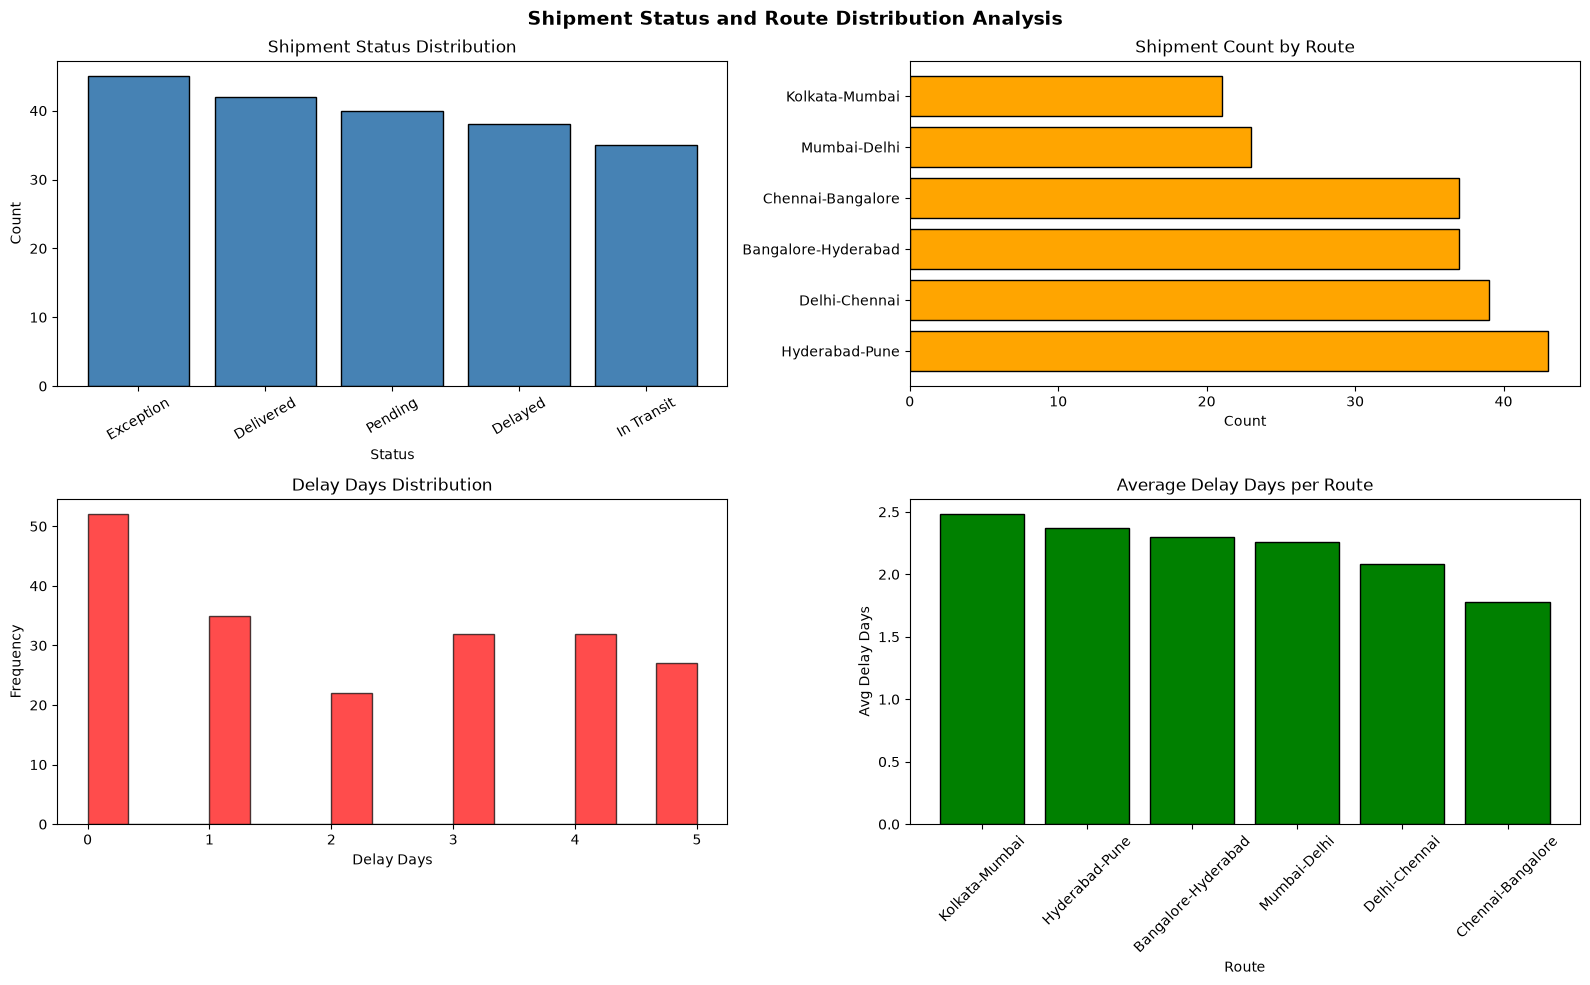

Plot saved.


In [46]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

status_counts = shipments_df["status"].value_counts()
axes[0][0].bar(status_counts.index, status_counts.values, color="steelblue", edgecolor="black")
axes[0][0].set_title("Shipment Status Distribution")
axes[0][0].set_xlabel("Status")
axes[0][0].set_ylabel("Count")
axes[0][0].tick_params(axis="x", rotation=30)

route_counts = shipments_df["route"].value_counts()
axes[0][1].barh(route_counts.index, route_counts.values, color="orange", edgecolor="black")
axes[0][1].set_title("Shipment Count by Route")
axes[0][1].set_xlabel("Count")

axes[1][0].hist(shipments_df["delay_days"], bins=15, color="red", edgecolor="black", alpha=0.7)
axes[1][0].set_title("Delay Days Distribution")
axes[1][0].set_xlabel("Delay Days")
axes[1][0].set_ylabel("Frequency")

route_delay = shipments_df.groupby("route")["delay_days"].mean().round(2).sort_values(ascending=False)
axes[1][1].bar(route_delay.index, route_delay.values, color="green", edgecolor="black")
axes[1][1].set_title("Average Delay Days per Route")
axes[1][1].set_xlabel("Route")
axes[1][1].set_ylabel("Avg Delay Days")
axes[1][1].tick_params(axis="x", rotation=45)

plt.suptitle("Shipment Status and Route Distribution Analysis", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("shipment_eda.png", dpi=150)
plt.show()
print("Plot saved.")

# EDA — Exception Type, Severity, and Resolution Analysis

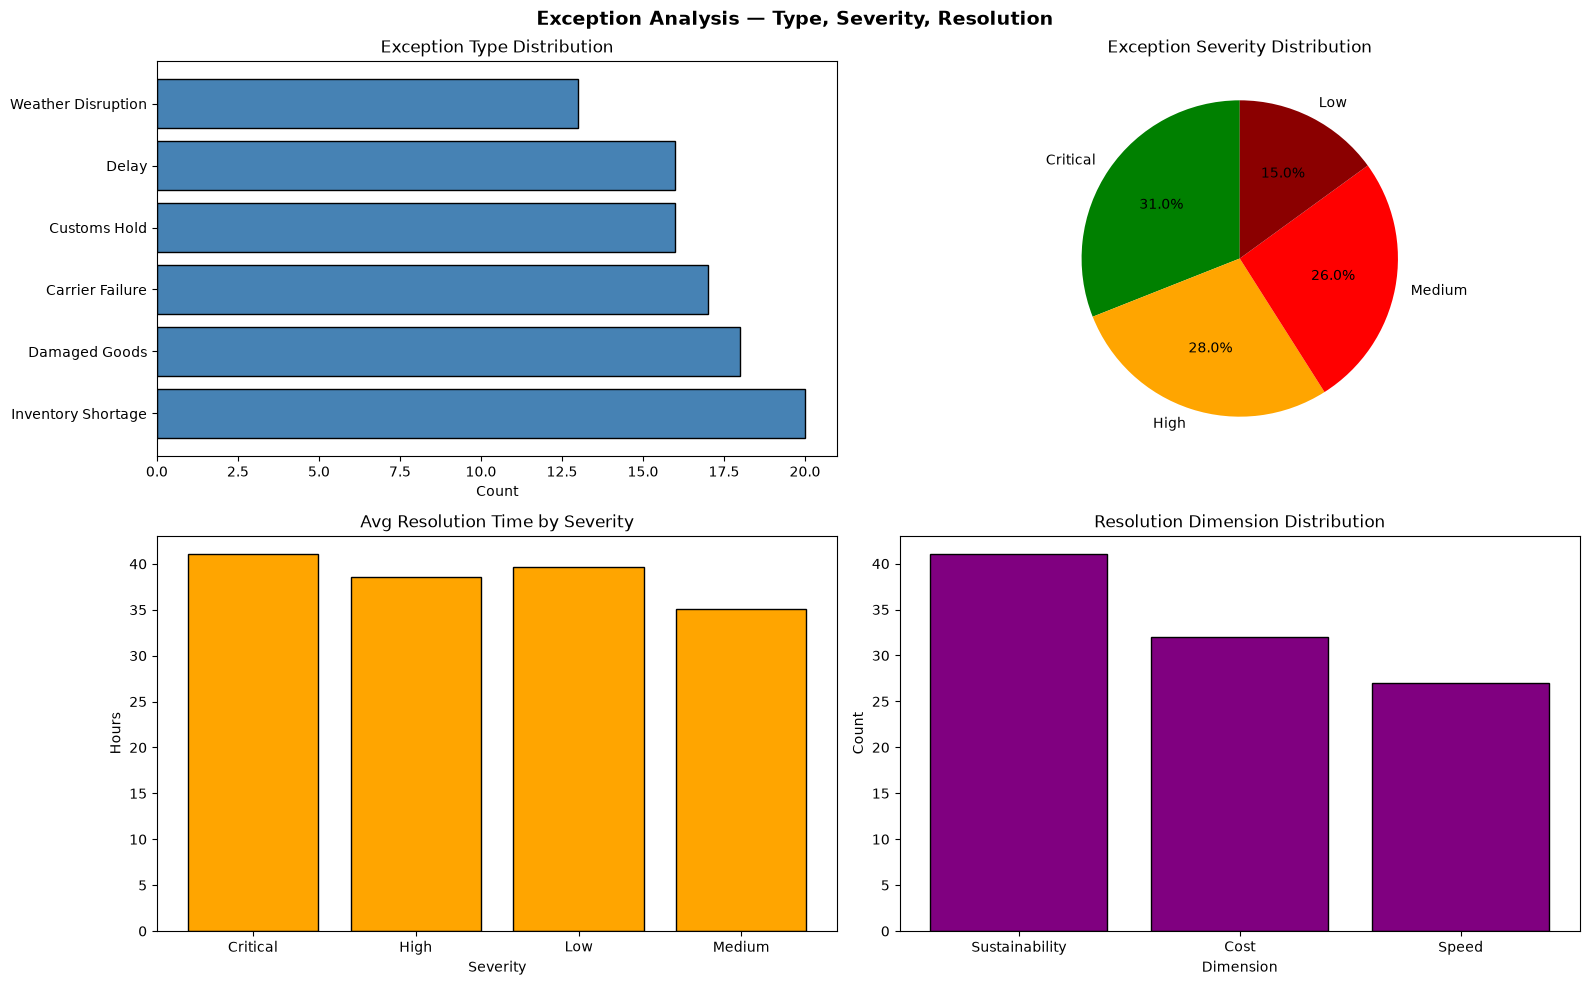

Plot saved.


In [47]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

exc_type_counts = exceptions_df["exception_type"].value_counts()
axes[0][0].barh(exc_type_counts.index, exc_type_counts.values, color="steelblue", edgecolor="black")
axes[0][0].set_title("Exception Type Distribution")
axes[0][0].set_xlabel("Count")

severity_counts = exceptions_df["severity"].value_counts()
colors = ["green", "orange", "red", "darkred"]
axes[0][1].pie(severity_counts.values, labels=severity_counts.index,
               autopct="%1.1f%%", colors=colors, startangle=90)
axes[0][1].set_title("Exception Severity Distribution")

res_time_severity = exceptions_df.groupby("severity")["resolution_time_hours"].mean().round(2)
axes[1][0].bar(res_time_severity.index, res_time_severity.values, color="orange", edgecolor="black")
axes[1][0].set_title("Avg Resolution Time by Severity")
axes[1][0].set_xlabel("Severity")
axes[1][0].set_ylabel("Hours")

dim_counts = exceptions_df["resolution_dimension"].value_counts()
axes[1][1].bar(dim_counts.index, dim_counts.values, color="purple", edgecolor="black")
axes[1][1].set_title("Resolution Dimension Distribution")
axes[1][1].set_xlabel("Dimension")
axes[1][1].set_ylabel("Count")

plt.suptitle("Exception Analysis — Type, Severity, Resolution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("exception_eda.png", dpi=150)
plt.show()
print("Plot saved.")

# EDA — Weather Impact on Shipment Delays

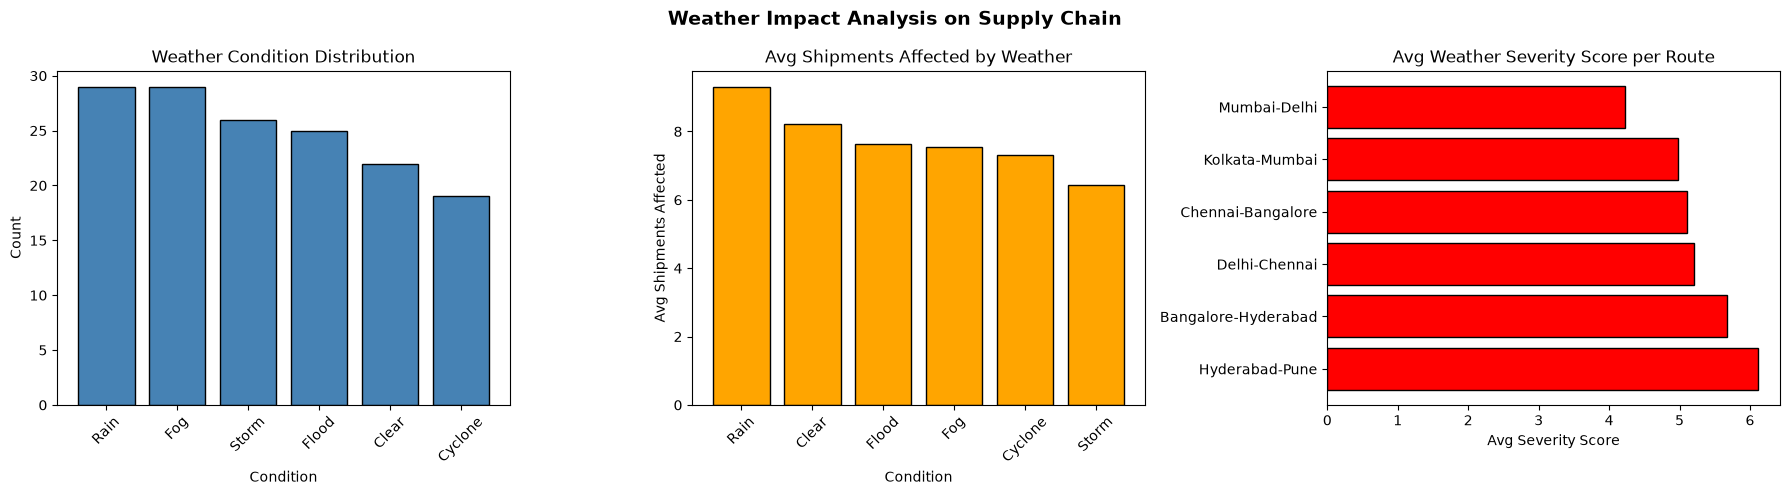

Plot saved.


In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

weather_counts = weather_df["condition"].value_counts()
axes[0].bar(weather_counts.index, weather_counts.values, color="steelblue", edgecolor="black")
axes[0].set_title("Weather Condition Distribution")
axes[0].set_xlabel("Condition")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

weather_impact = weather_df.groupby("condition")["shipments_affected"].mean().round(2).sort_values(ascending=False)
axes[1].bar(weather_impact.index, weather_impact.values, color="orange", edgecolor="black")
axes[1].set_title("Avg Shipments Affected by Weather")
axes[1].set_xlabel("Condition")
axes[1].set_ylabel("Avg Shipments Affected")
axes[1].tick_params(axis="x", rotation=45)

route_weather = weather_df.groupby("route")["severity_score"].mean().round(2).sort_values(ascending=False)
axes[2].barh(route_weather.index, route_weather.values, color="red", edgecolor="black")
axes[2].set_title("Avg Weather Severity Score per Route")
axes[2].set_xlabel("Avg Severity Score")

plt.suptitle("Weather Impact Analysis on Supply Chain", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("weather_impact.png", dpi=150)
plt.show()
print("Plot saved.")

# Anomaly Detection — ML Based Pattern Detection

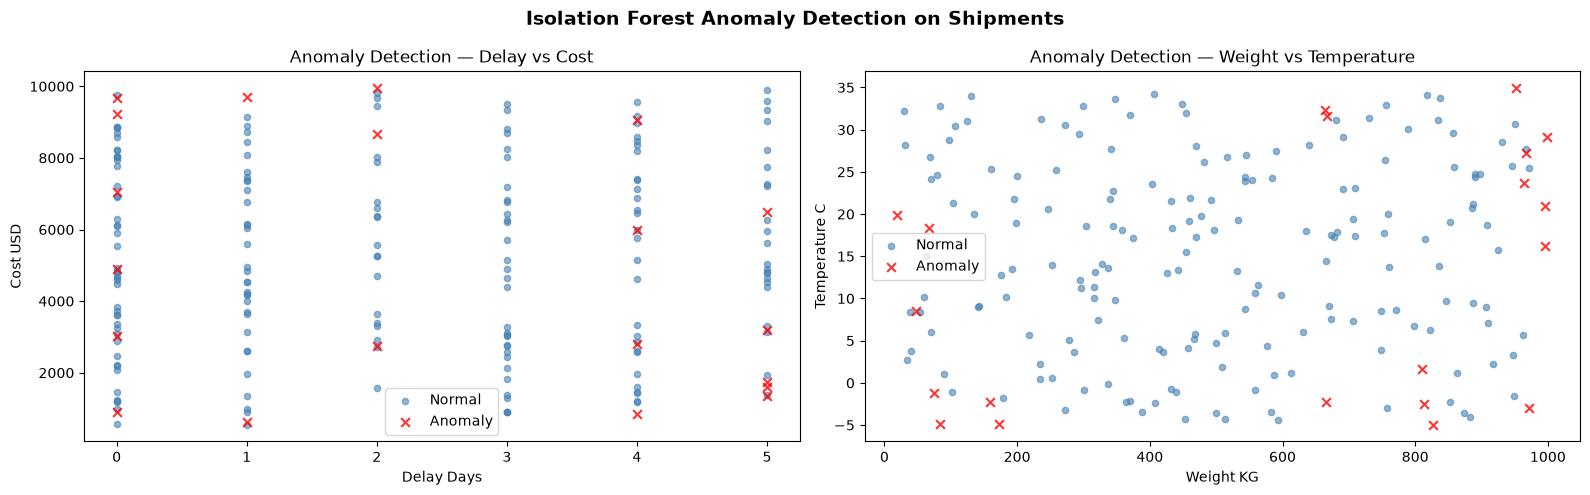

Total Shipments  : 200
Anomalies Detected : 20
Normal Shipments   : 180

   shipment_id                route  delay_days  cost_usd  weight_kg
13    SHP_0014        Delhi-Chennai           2   8677.41     996.16
20    SHP_0021       Kolkata-Mumbai           4   9046.33     995.20
28    SHP_0029        Delhi-Chennai           0   3019.43     172.99
30    SHP_0031  Bangalore-Hyderabad           0   9234.18      66.59
34    SHP_0035       Kolkata-Mumbai           2   9962.92      19.22
71    SHP_0072       Hyderabad-Pune           0   9664.85     964.10
74    SHP_0075       Hyderabad-Pune           1    620.20     664.91
91    SHP_0092    Chennai-Bangalore           0   7049.03      84.31


In [49]:
from sklearn.ensemble import IsolationForest

features = shipments_df[["delay_days", "weight_kg", "temperature_c", "cost_usd"]].copy()
scaler_temp = MinMaxScaler()
features_scaled = scaler_temp.fit_transform(features)

iso_forest = IsolationForest(contamination=0.1, random_state=42)
shipments_df["anomaly_score"] = iso_forest.fit_predict(features_scaled)
shipments_df["is_anomaly"] = shipments_df["anomaly_score"].apply(lambda x: 1 if x == -1 else 0)

anomalies = shipments_df[shipments_df["is_anomaly"] == 1]
normal = shipments_df[shipments_df["is_anomaly"] == 0]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].scatter(normal["delay_days"], normal["cost_usd"],
                color="steelblue", alpha=0.6, label="Normal", s=20)
axes[0].scatter(anomalies["delay_days"], anomalies["cost_usd"],
                color="red", alpha=0.8, label="Anomaly", s=40, marker="x")
axes[0].set_title("Anomaly Detection — Delay vs Cost")
axes[0].set_xlabel("Delay Days")
axes[0].set_ylabel("Cost USD")
axes[0].legend()

axes[1].scatter(normal["weight_kg"], normal["temperature_c"],
                color="steelblue", alpha=0.6, label="Normal", s=20)
axes[1].scatter(anomalies["weight_kg"], anomalies["temperature_c"],
                color="red", alpha=0.8, label="Anomaly", s=40, marker="x")
axes[1].set_title("Anomaly Detection — Weight vs Temperature")
axes[1].set_xlabel("Weight KG")
axes[1].set_ylabel("Temperature C")
axes[1].legend()

plt.suptitle("Isolation Forest Anomaly Detection on Shipments", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("anomaly_detection.png", dpi=150)
plt.show()

print(f"Total Shipments  : {len(shipments_df)}")
print(f"Anomalies Detected : {shipments_df['is_anomaly'].sum()}")
print(f"Normal Shipments   : {(shipments_df['is_anomaly'] == 0).sum()}")
print()
print(anomalies[["shipment_id", "route", "delay_days", "cost_usd", "weight_kg"]].head(8).to_string())

# Strategy Generation Schema — Speed, Cost, Sustainability

In [50]:
def generate_resolution_strategies(exception):
    strategies = {
        "exception_id": exception["exception_id"],
        "exception_type": exception["exception_type"],
        "severity": exception["severity"],
        "strategies": {
            "Speed": {
                "dimension": "Speed",
                "action": f"Expedite via air freight for {exception['exception_type']}",
                "estimated_resolution_hours": random.randint(4, 12),
                "estimated_cost_usd": round(random.uniform(2000, 8000), 2),
                "carbon_footprint_kg": round(random.uniform(50, 200), 2),
                "feasibility_score": round(random.uniform(0.7, 1.0), 2)
            },
            "Cost": {
                "dimension": "Cost",
                "action": f"Use ground transport with rerouting for {exception['exception_type']}",
                "estimated_resolution_hours": random.randint(24, 72),
                "estimated_cost_usd": round(random.uniform(200, 1000), 2),
                "carbon_footprint_kg": round(random.uniform(20, 80), 2),
                "feasibility_score": round(random.uniform(0.6, 0.9), 2)
            },
            "Sustainability": {
                "dimension": "Sustainability",
                "action": f"Use rail or electric vehicle network for {exception['exception_type']}",
                "estimated_resolution_hours": random.randint(36, 96),
                "estimated_cost_usd": round(random.uniform(500, 2000), 2),
                "carbon_footprint_kg": round(random.uniform(5, 30), 2),
                "feasibility_score": round(random.uniform(0.5, 0.85), 2)
            }
        }
    }
    return strategies

sample_exception = exceptions_df.iloc[0].to_dict()
strategies = generate_resolution_strategies(sample_exception)

print("=== Strategy Generation Output ===")
print(f"Exception ID    : {strategies['exception_id']}")
print(f"Exception Type  : {strategies['exception_type']}")
print(f"Severity        : {strategies['severity']}")
print()
for dim, strat in strategies["strategies"].items():
    print(f"  [{dim}]")
    for k, v in strat.items():
        print(f"    {k:<30}: {v}")
    print()

=== Strategy Generation Output ===
Exception ID    : EXC_0001
Exception Type  : Inventory Shortage
Severity        : Low

  [Speed]
    dimension                     : Speed
    action                        : Expedite via air freight for Inventory Shortage
    estimated_resolution_hours    : 8
    estimated_cost_usd            : 4676.07
    carbon_footprint_kg           : 72.29
    feasibility_score             : 0.88

  [Cost]
    dimension                     : Cost
    action                        : Use ground transport with rerouting for Inventory Shortage
    estimated_resolution_hours    : 63
    estimated_cost_usd            : 396.63
    carbon_footprint_kg           : 37.71
    feasibility_score             : 0.72

  [Sustainability]
    dimension                     : Sustainability
    action                        : Use rail or electric vehicle network for Inventory Shortage
    estimated_resolution_hours    : 71
    estimated_cost_usd            : 1218.55
    carbon_footp

# Auditor Node Constraint Validation Logic

In [51]:
COMPLIANCE_CONSTRAINTS = {
    "weight_limit": 900,
    "temperature_min": -5,
    "temperature_max": 35,
    "max_resolution_hours": 72,
    "min_feasibility_score": 0.6
}

def validate_strategy(strategy, shipment):
    violations = []
    passed = []

    if shipment["weight_kg"] > COMPLIANCE_CONSTRAINTS["weight_limit"]:
        violations.append(f"Weight {shipment['weight_kg']} kg exceeds limit {COMPLIANCE_CONSTRAINTS['weight_limit']} kg")
    else:
        passed.append("weight_limit")

    if not (COMPLIANCE_CONSTRAINTS["temperature_min"] <= shipment["temperature_c"] <= COMPLIANCE_CONSTRAINTS["temperature_max"]):
        violations.append(f"Temperature {shipment['temperature_c']}C out of range")
    else:
        passed.append("temperature_range")

    for dim, strat in strategy["strategies"].items():
        if strat["estimated_resolution_hours"] > COMPLIANCE_CONSTRAINTS["max_resolution_hours"]:
            violations.append(f"{dim} strategy exceeds max resolution time")
        if strat["feasibility_score"] < COMPLIANCE_CONSTRAINTS["min_feasibility_score"]:
            violations.append(f"{dim} strategy below minimum feasibility score")

    return {
        "exception_id": strategy["exception_id"],
        "passed_checks": passed,
        "violations": violations,
        "audit_result": "APPROVED" if len(violations) == 0 else "REJECTED",
        "total_checks": len(passed) + len(violations)
    }

sample_shipment = shipments_df.iloc[0].to_dict()
audit_result = validate_strategy(strategies, sample_shipment)

print("=== Auditor Node Validation Output ===")
for k, v in audit_result.items():
    print(f"{k:<20}: {v}")

=== Auditor Node Validation Output ===
exception_id        : EXC_0001
passed_checks       : ['weight_limit', 'temperature_range']
violations          : []
audit_result        : APPROVED
total_checks        : 2


# Agent Workflow State Schema and Exception Lifecycle

In [52]:
workflow_state_schema = {
    "state_id": "STATE_001",
    "shipment_id": "SHP_0071",
    "current_node": "Monitoring Node",
    "completed_nodes": [],
    "exception_detected": False,
    "exception_details": None,
    "retrieved_context": None,
    "generated_strategies": None,
    "audit_result": None,
    "execution_status": None,
    "notifications_sent": [],
    "created_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "last_updated": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

exception_lifecycle = {
    "step_1": {"node": "Monitoring Node",         "action": "Detect anomaly via IsolationForest + weather API"},
    "step_2": {"node": "Context Retrieval Node",  "action": "Query Chroma vector DB for relevant SOPs and precedent cases"},
    "step_3": {"node": "Strategy Generation Node","action": "Generate Speed, Cost, Sustainability strategies via Gemini"},
    "step_4": {"node": "Auditor Node",            "action": "Validate strategies against compliance constraints"},
    "step_5": {"node": "Execution Node",          "action": "Execute approved strategy and send notifications"}
}

print("=== Agent Workflow State Schema ===")
print(json.dumps(workflow_state_schema, indent=2))
print()
print("=== Exception Lifecycle — 5 Node Flow ===")
for step, details in exception_lifecycle.items():
    print(f"  {step} | {details['node']:<30} | {details['action']}")

=== Agent Workflow State Schema ===
{
  "state_id": "STATE_001",
  "shipment_id": "SHP_0071",
  "current_node": "Monitoring Node",
  "completed_nodes": [],
  "exception_detected": false,
  "exception_details": null,
  "retrieved_context": null,
  "generated_strategies": null,
  "audit_result": null,
  "execution_status": null,
  "notifications_sent": [],
  "created_at": "2026-08-16 22:54:07",
  "last_updated": "2026-08-16 22:54:07"
}

=== Exception Lifecycle — 5 Node Flow ===
  step_1 | Monitoring Node                | Detect anomaly via IsolationForest + weather API
  step_2 | Context Retrieval Node         | Query Chroma vector DB for relevant SOPs and precedent cases
  step_3 | Strategy Generation Node       | Generate Speed, Cost, Sustainability strategies via Gemini
  step_4 | Auditor Node                   | Validate strategies against compliance constraints
  step_5 | Execution Node                 | Execute approved strategy and send notifications


# Correlation Analysis — Weather vs Exception Rate

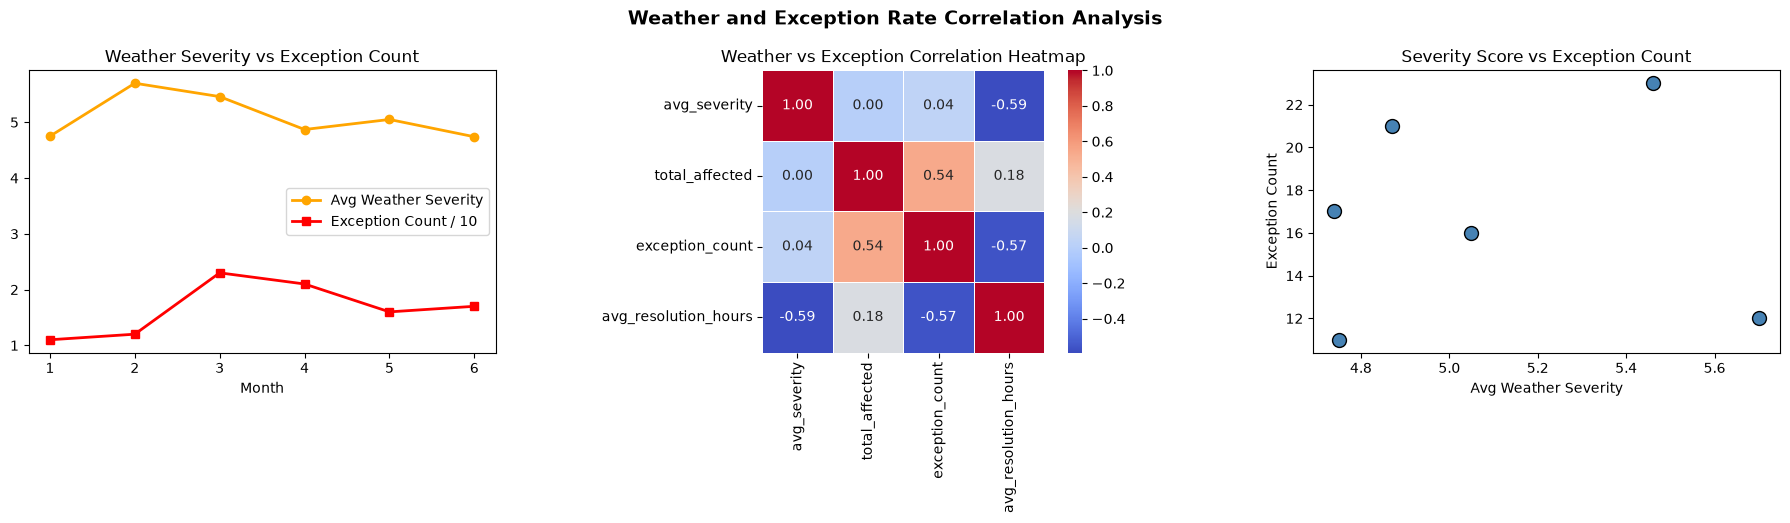

Plot saved.


In [53]:
weather_df["event_date"] = pd.to_datetime(weather_df["event_date"])
exceptions_df["detected_date"] = pd.to_datetime(exceptions_df["detected_date"])

weather_monthly = weather_df.groupby(weather_df["event_date"].dt.month).agg(
    avg_severity=("severity_score", "mean"),
    total_affected=("shipments_affected", "sum"),
    event_count=("event_id", "count")
).round(2)

exception_monthly = exceptions_df.groupby(exceptions_df["detected_date"].dt.month).agg(
    exception_count=("exception_id", "count"),
    avg_resolution_hours=("resolution_time_hours", "mean")
).round(2)

monthly_combined = weather_monthly.join(exception_monthly, how="inner")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(monthly_combined.index, monthly_combined["avg_severity"],
             marker="o", color="orange", linewidth=2, label="Avg Weather Severity")
axes[0].plot(monthly_combined.index, monthly_combined["exception_count"] / 10,
             marker="s", color="red", linewidth=2, label="Exception Count / 10")
axes[0].set_title("Weather Severity vs Exception Count")
axes[0].set_xlabel("Month")
axes[0].legend()

corr_matrix = monthly_combined[["avg_severity", "total_affected", "exception_count", "avg_resolution_hours"]].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            ax=axes[1], linewidths=0.5, square=True)
axes[1].set_title("Weather vs Exception Correlation Heatmap")

axes[2].scatter(monthly_combined["avg_severity"],
                monthly_combined["exception_count"],
                color="steelblue", s=100, edgecolors="black")
axes[2].set_title("Severity Score vs Exception Count")
axes[2].set_xlabel("Avg Weather Severity")
axes[2].set_ylabel("Exception Count")

plt.suptitle("Weather and Exception Rate Correlation Analysis", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("weather_exception_correlation.png", dpi=150)
plt.show()
print("Plot saved.")

# Preprocessing — Encoding and Normalization

In [54]:
le = LabelEncoder()
scaler = MinMaxScaler()

shipments_df["route_enc"] = le.fit_transform(shipments_df["route"])
shipments_df["status_enc"] = le.fit_transform(shipments_df["status"])
shipments_df["carrier_enc"] = le.fit_transform(shipments_df["carrier"])
shipments_df["delay_norm"] = scaler.fit_transform(shipments_df[["delay_days"]])
shipments_df["cost_norm"] = scaler.fit_transform(shipments_df[["cost_usd"]])
shipments_df["weight_norm"] = scaler.fit_transform(shipments_df[["weight_kg"]])

exceptions_df["exception_type_enc"] = le.fit_transform(exceptions_df["exception_type"])
exceptions_df["severity_enc"] = le.fit_transform(exceptions_df["severity"])
exceptions_df["resolution_dim_enc"] = le.fit_transform(exceptions_df["resolution_dimension"])
exceptions_df["resolution_norm"] = scaler.fit_transform(exceptions_df[["resolution_time_hours"]])
exceptions_df["resolved_enc"] = exceptions_df["resolved"].astype(int)

weather_df["condition_enc"] = le.fit_transform(weather_df["condition"])
weather_df["route_enc"] = le.fit_transform(weather_df["route"])
weather_df["severity_norm"] = scaler.fit_transform(weather_df[["severity_score"]])

print("=== Preprocessing Summary ===")
print("Shipments   : route_enc, status_enc, carrier_enc, delay_norm, cost_norm, weight_norm")
print("Exceptions  : exception_type_enc, severity_enc, resolution_dim_enc, resolution_norm, resolved_enc")
print("Weather     : condition_enc, route_enc, severity_norm")
print()
print("Sample Shipment Preprocessed:")
print(shipments_df[["shipment_id", "route", "route_enc", "delay_days", "delay_norm", "is_anomaly"]].head(5).to_string())

=== Preprocessing Summary ===
Shipments   : route_enc, status_enc, carrier_enc, delay_norm, cost_norm, weight_norm
Exceptions  : exception_type_enc, severity_enc, resolution_dim_enc, resolution_norm, resolved_enc
Weather     : condition_enc, route_enc, severity_norm

Sample Shipment Preprocessed:
  shipment_id                route  route_enc  delay_days  delay_norm  is_anomaly
0    SHP_0001  Bangalore-Hyderabad          0           0         0.0           0
1    SHP_0002        Delhi-Chennai          2           3         0.6           0
2    SHP_0003  Bangalore-Hyderabad          0           4         0.8           0
3    SHP_0004        Delhi-Chennai          2           4         0.8           0
4    SHP_0005       Kolkata-Mumbai          4           1         0.2           0


# EDA — Agent Node Workload Distribution

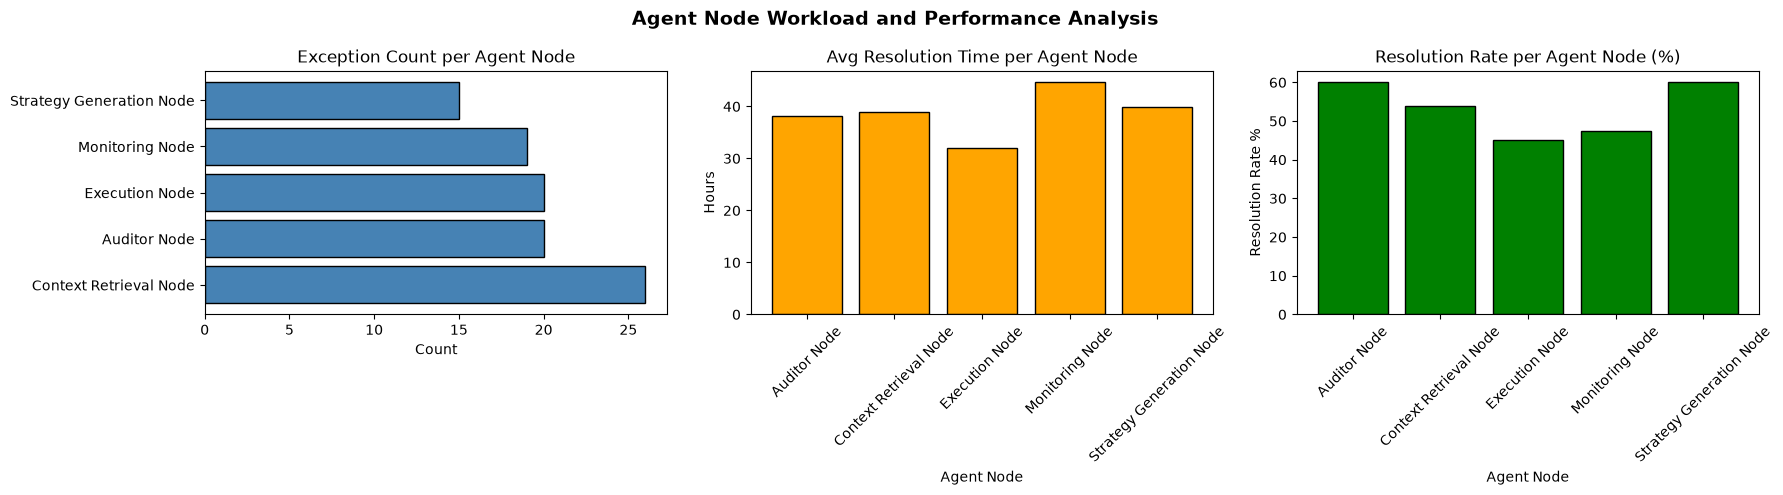

Plot saved.


In [55]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

node_counts = exceptions_df["agent_node"].value_counts()
axes[0].barh(node_counts.index, node_counts.values, color="steelblue", edgecolor="black")
axes[0].set_title("Exception Count per Agent Node")
axes[0].set_xlabel("Count")

node_resolution = exceptions_df.groupby("agent_node")["resolution_time_hours"].mean().round(2)
axes[1].bar(node_resolution.index, node_resolution.values, color="orange", edgecolor="black")
axes[1].set_title("Avg Resolution Time per Agent Node")
axes[1].set_xlabel("Agent Node")
axes[1].set_ylabel("Hours")
axes[1].tick_params(axis="x", rotation=45)

resolved_by_node = exceptions_df.groupby("agent_node")["resolved_enc"].mean() * 100
axes[2].bar(resolved_by_node.index, resolved_by_node.values, color="green", edgecolor="black")
axes[2].set_title("Resolution Rate per Agent Node (%)")
axes[2].set_xlabel("Agent Node")
axes[2].set_ylabel("Resolution Rate %")
axes[2].tick_params(axis="x", rotation=45)

plt.suptitle("Agent Node Workload and Performance Analysis", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("agent_node_analysis.png", dpi=150)
plt.show()
print("Plot saved.")

# RAG Document Retrieval Simulation

In [56]:
def retrieve_relevant_docs(exception_type, sop_documents, precedent_cases):
    relevant_sops = [
        doc for doc in sop_documents
        if exception_type in doc["applicable_exceptions"]
    ]
    relevant_cases = [
        case for case in precedent_cases
        if case["exception_type"] == exception_type
    ]
    return {
        "exception_type": exception_type,
        "relevant_sops": relevant_sops,
        "relevant_cases": relevant_cases,
        "total_docs_retrieved": len(relevant_sops) + len(relevant_cases)
    }

test_types = ["Weather Disruption", "Customs Hold", "Carrier Failure"]
print("=== RAG Context Retrieval Simulation ===")
for exc_type in test_types:
    result = retrieve_relevant_docs(exc_type, sop_documents, precedent_cases)
    print(f"\nException Type      : {result['exception_type']}")
    print(f"SOPs Retrieved      : {len(result['relevant_sops'])}")
    print(f"Cases Retrieved     : {len(result['relevant_cases'])}")
    print(f"Total Docs          : {result['total_docs_retrieved']}")
    if result["relevant_sops"]:
        print(f"SOP Title           : {result['relevant_sops'][0]['title']}")
    if result["relevant_cases"]:
        print(f"Case Resolution     : {result['relevant_cases'][0]['resolution_summary']}")

=== RAG Context Retrieval Simulation ===

Exception Type      : Weather Disruption
SOPs Retrieved      : 1
Cases Retrieved     : 1
Total Docs          : 2
SOP Title           : Weather Disruption Response Protocol
Case Resolution     : Rerouted via air freight. Delivered within 6 hours of exception detection.

Exception Type      : Customs Hold
SOPs Retrieved      : 1
Cases Retrieved     : 1
Total Docs          : 2
SOP Title           : Customs Hold Resolution Procedure
Case Resolution     : Engaged customs broker. Submitted all documentation. Cleared in 18 hours.

Exception Type      : Carrier Failure
SOPs Retrieved      : 1
Cases Retrieved     : 1
Total Docs          : 2
SOP Title           : Carrier Failure Contingency Plan
Case Resolution     : Switched to rail freight. Longer transit but lower emissions and cost.


# Preprocessing Validation and Dataset Summary

In [57]:
print("=== Final Dataset Validation ===")
print()
print(f"Shipments Dataset")
print(f"  Records          : {len(shipments_df)}")
print(f"  Columns          : {len(shipments_df.columns)}")
print(f"  Anomalies        : {shipments_df['is_anomaly'].sum()}")
print(f"  Missing Values   : {shipments_df.isnull().sum().sum()}")
print()
print(f"Exceptions Dataset")
print(f"  Records          : {len(exceptions_df)}")
print(f"  Columns          : {len(exceptions_df.columns)}")
print(f"  Resolved         : {exceptions_df['resolved_enc'].sum()}")
print(f"  Missing Values   : {exceptions_df.isnull().sum().sum()}")
print()
print(f"Weather Events Dataset")
print(f"  Records          : {len(weather_df)}")
print(f"  Columns          : {len(weather_df.columns)}")
print(f"  Missing Values   : {weather_df.isnull().sum().sum()}")
print()
print(f"SOP Documents      : {len(sop_documents)}")
print(f"Precedent Cases    : {len(precedent_cases)}")
print()
print("Encoded Columns — Shipments :")
print(" ", [c for c in shipments_df.columns if "_enc" in c or "_norm" in c])
print("Encoded Columns — Exceptions :")
print(" ", [c for c in exceptions_df.columns if "_enc" in c or "_norm" in c])
print("Encoded Columns — Weather :")
print(" ", [c for c in weather_df.columns if "_enc" in c or "_norm" in c])

=== Final Dataset Validation ===

Shipments Dataset
  Records          : 200
  Columns          : 19
  Anomalies        : 20
  Missing Values   : 0

Exceptions Dataset
  Records          : 100
  Columns          : 14
  Resolved         : 53
  Missing Values   : 0

Weather Events Dataset
  Records          : 150
  Columns          : 10
  Missing Values   : 0

SOP Documents      : 5
Precedent Cases    : 5

Encoded Columns — Shipments :
  ['route_enc', 'status_enc', 'carrier_enc', 'delay_norm', 'cost_norm', 'weight_norm']
Encoded Columns — Exceptions :
  ['exception_type_enc', 'severity_enc', 'resolution_dim_enc', 'resolution_norm', 'resolved_enc']
Encoded Columns — Weather :
  ['condition_enc', 'route_enc', 'severity_norm']


# Final Module 1 Summary Report

In [58]:
print("=" * 65)
print("  MODULE 1 — SUPPLY CHAIN EXCEPTION SYSTEM SUMMARY")
print("=" * 65)

print("\n[1] PROJECT")
print("    Autonomous Multi-Agent RAG-Driven Supply Chain Framework")
print(f"    Agent Nodes          : {', '.join(AGENT_NODES)}")
print(f"    Exception Types      : {', '.join(EXCEPTION_TYPES)}")
print(f"    Resolution Dimensions: {', '.join(RESOLUTION_DIMENSIONS)}")

print("\n[2] DATA GENERATED")
print(f"    Shipments            : {len(shipments_df)}")
print(f"    Exceptions           : {len(exceptions_df)}")
print(f"    Weather Events       : {len(weather_df)}")
print(f"    SOP Documents        : {len(sop_documents)}")
print(f"    Precedent Cases      : {len(precedent_cases)}")

  MODULE 1 — SUPPLY CHAIN EXCEPTION SYSTEM SUMMARY

[1] PROJECT
    Autonomous Multi-Agent RAG-Driven Supply Chain Framework
    Agent Nodes          : Monitoring Node, Context Retrieval Node, Strategy Generation Node, Auditor Node, Execution Node
    Exception Types      : Delay, Damaged Goods, Weather Disruption, Customs Hold, Carrier Failure, Inventory Shortage
    Resolution Dimensions: Speed, Cost, Sustainability

[2] DATA GENERATED
    Shipments            : 200
    Exceptions           : 100
    Weather Events       : 150
    SOP Documents        : 5
    Precedent Cases      : 5
